In [36]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2




r_seed = 42

from pathlib import Path
WORKDIR = str(Path.cwd().parent) + '/'  # raiz do repositório
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/logs/"+data_hora

In [37]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [38]:
## get dataset

# select only sensor data from smart watches
data = pd.read_csv(WORKDIR + 'Data/processed/activity_recognition_data_watch_join_multi_index.csv')

In [39]:
data.head()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426757696641,4.972757,-0.158317,6.696732,0.314944,-1.022277,-0.309962
1,1600,0,90426807196641,3.253720,-0.191835,6.107758,0.387382,-0.618541,-0.048972
2,1600,0,90426856696641,2.801216,-0.155922,5.997625,0.070999,-0.209480,-0.195978
3,1600,0,90426906196641,3.770868,-1.051354,7.731027,0.037975,0.254976,-0.156563
4,1600,0,90426955696641,4.661511,0.169689,9.684695,0.073129,0.719431,-0.001035


In [40]:
data.isnull().sum()

pessoa_x          0
atividade         0
tempo             0
acelerômetro_x    0
acelerômetro_Y    0
acelerômetro_Z    0
giroscópio_x      0
giroscópio_Y      0
giroscópio_Z      0
dtype: int64

In [41]:
#remove the null class
data=data.dropna()

# **Data Exploration**

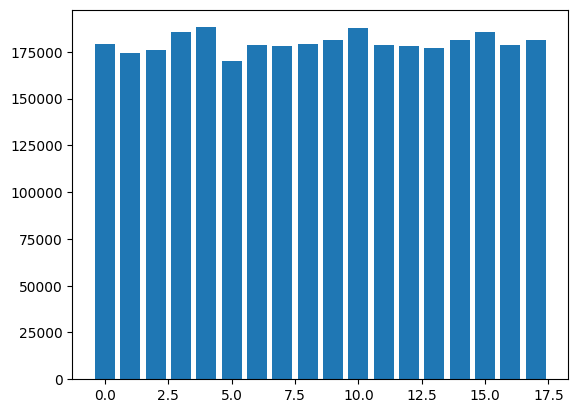

In [42]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

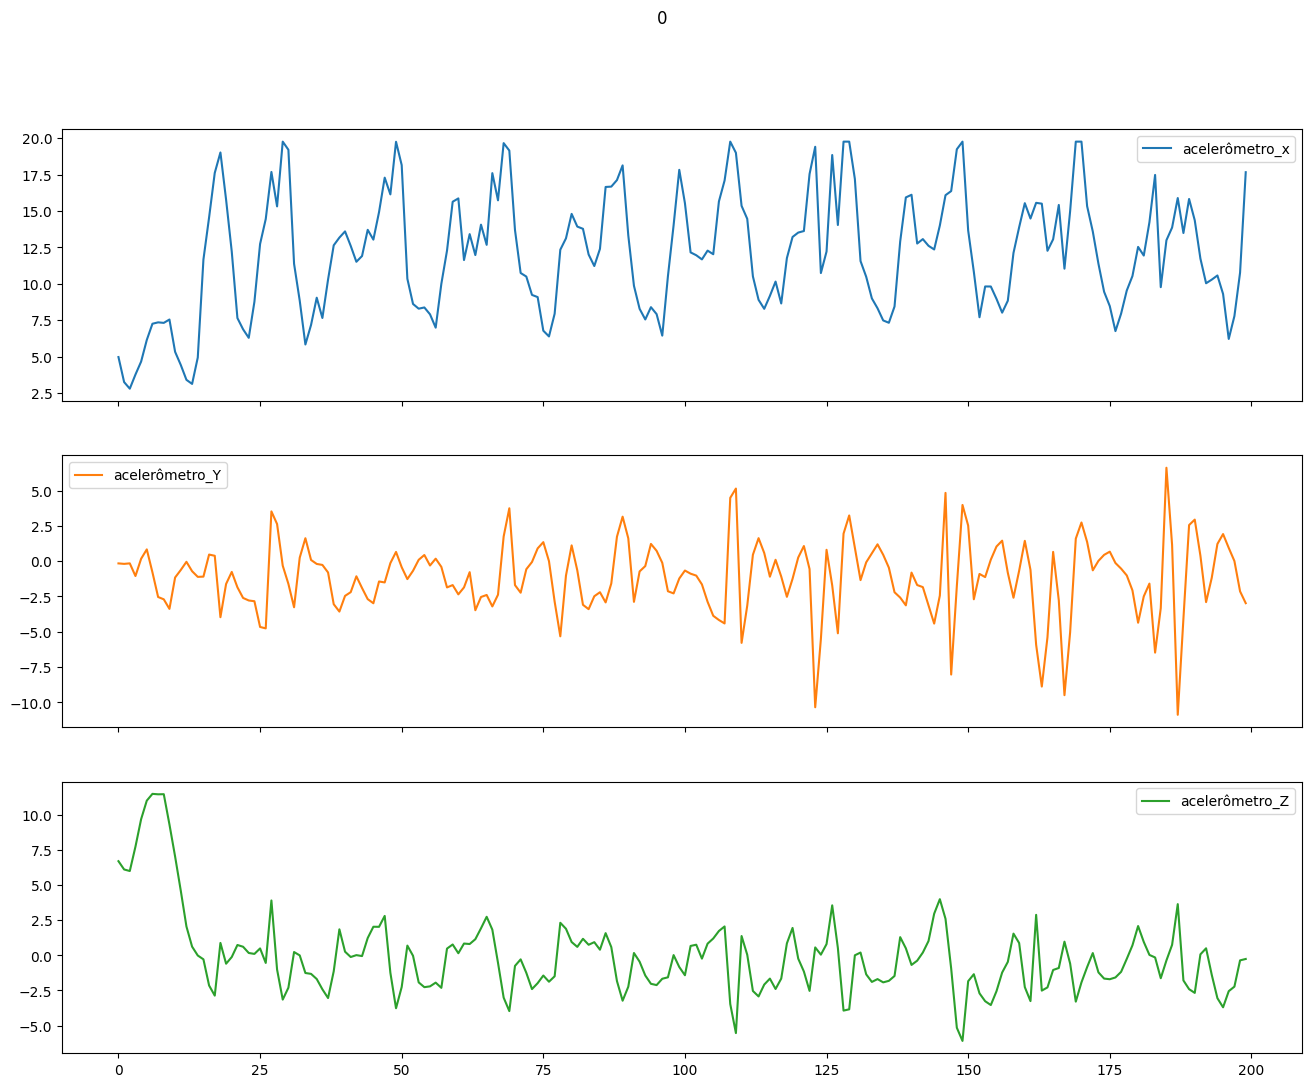

In [43]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['acelerômetro_x','acelerômetro_Y','acelerômetro_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

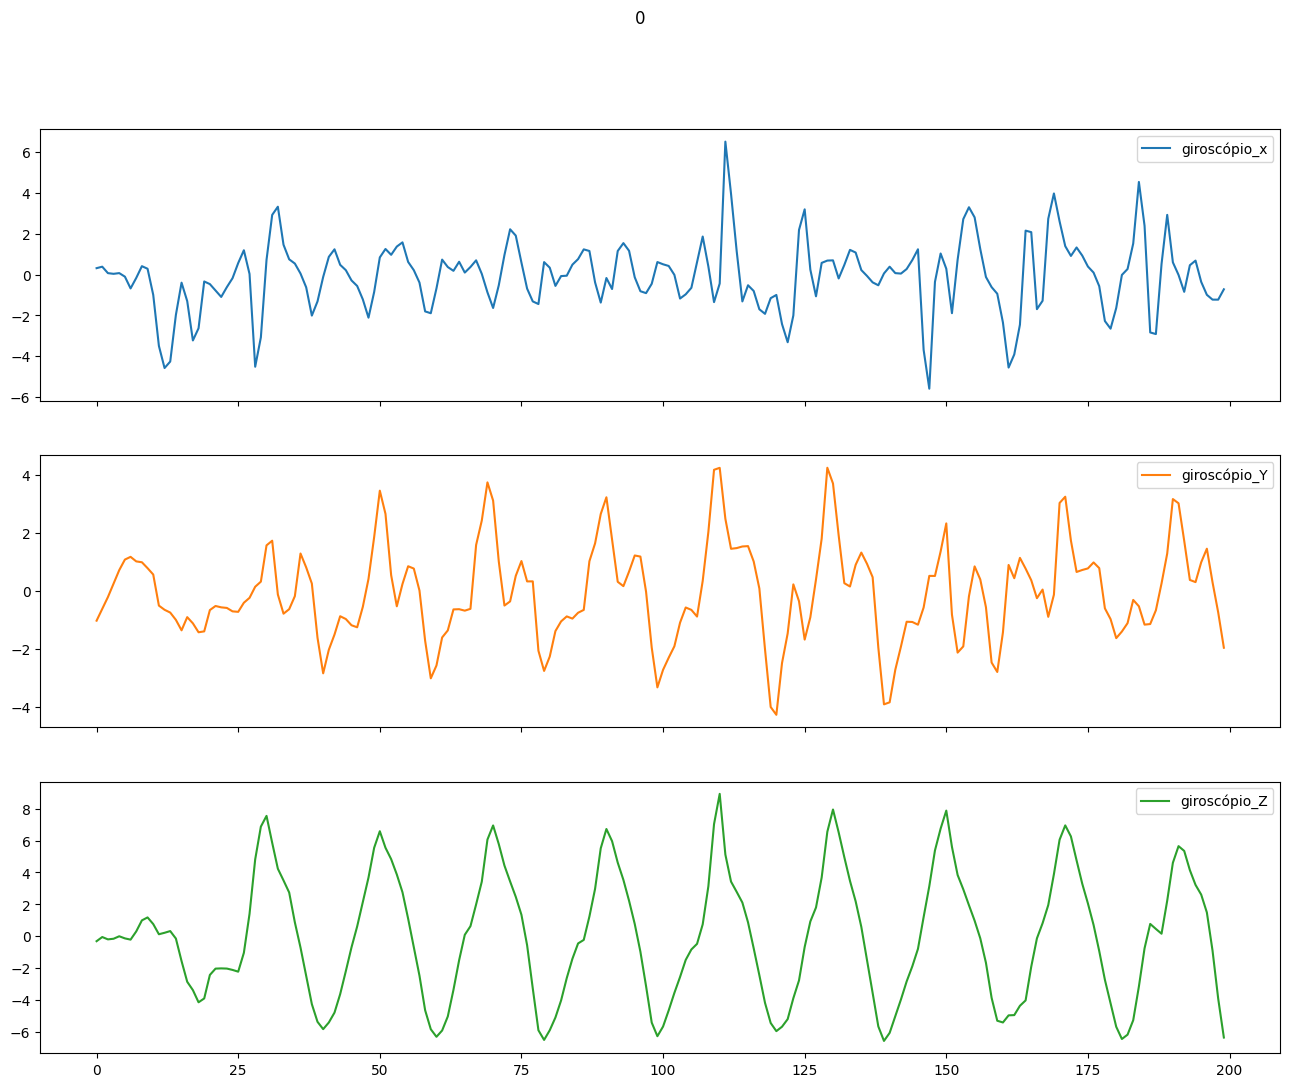

In [44]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['giroscópio_x','giroscópio_Y','giroscópio_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

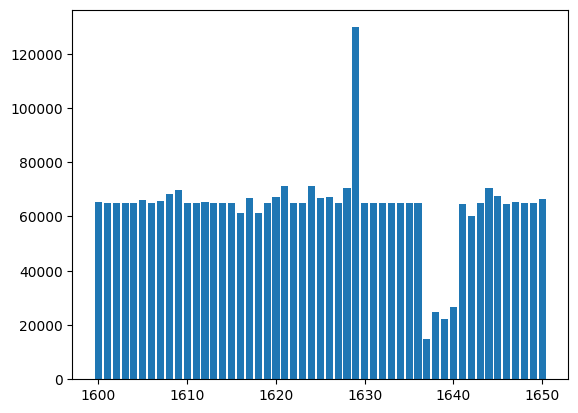

In [45]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

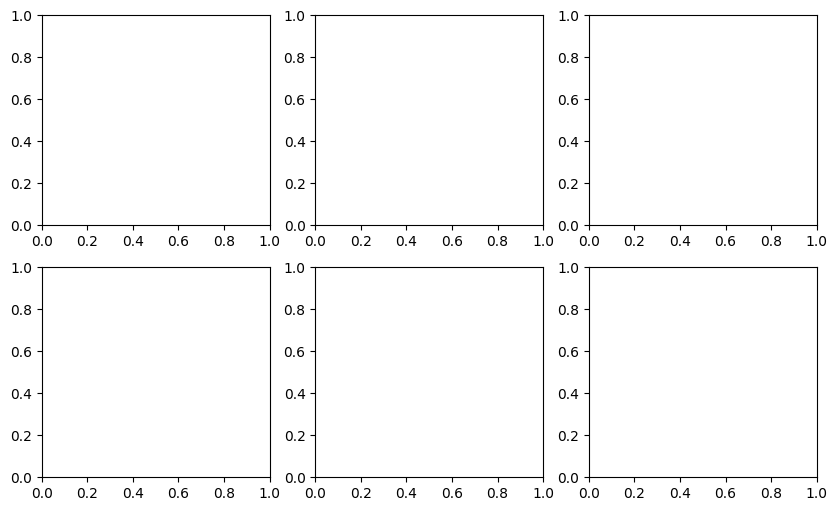

In [140]:
# Crie uma figura e subplots
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(10, 6))

# Crie uma lista de rótulos
labels = data.columns.tolist()

# Crie um objeto de legenda
legend = plt.legend(labels, loc="best", bbox_to_anchor=(1.04, 0.5), ncol=2)

# Gere um gráfico KDE para cada coluna em um subplot específico
for i, col in enumerate(data['acelerômetro_x',
       'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y',
       'giroscópio_Z']):
    ax = axes[i // 3, i % 3]
    sns.kdeplot(data[col], fill=True, color=col, ax=ax)
    ax.set_title(col)
    ax.add_artist(legend)

# Ajuste o layout e mostre o gráfico
fig.tight_layout()
plt.show()

In [131]:
data.columns

Index(['index', 'pessoa_x', 'atividade', 'tempo', 'acelerômetro_x',
       'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y',
       'giroscópio_Z'],
      dtype='object')

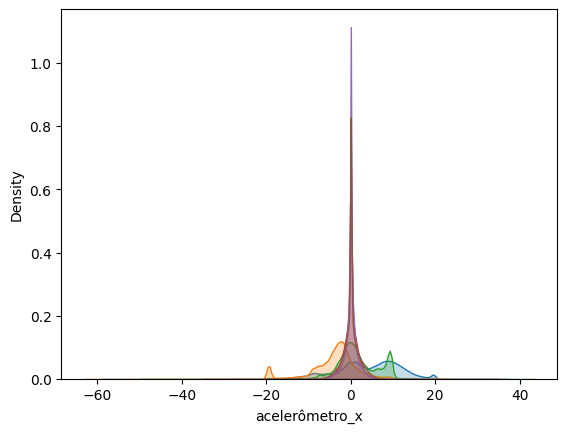

In [141]:
for col in data[['acelerômetro_x',
       'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y',
       'giroscópio_Z']]:
    sns.kdeplot(data[col], fill=True)

# Adicione títulos e rótulos aos eixos
plt.legend(True)
plt.title("Distribuição KDE dos dados")
plt.xlabel("Valor")
plt.ylabel("Densidade")

# Mostre o gráfico
plt.show()

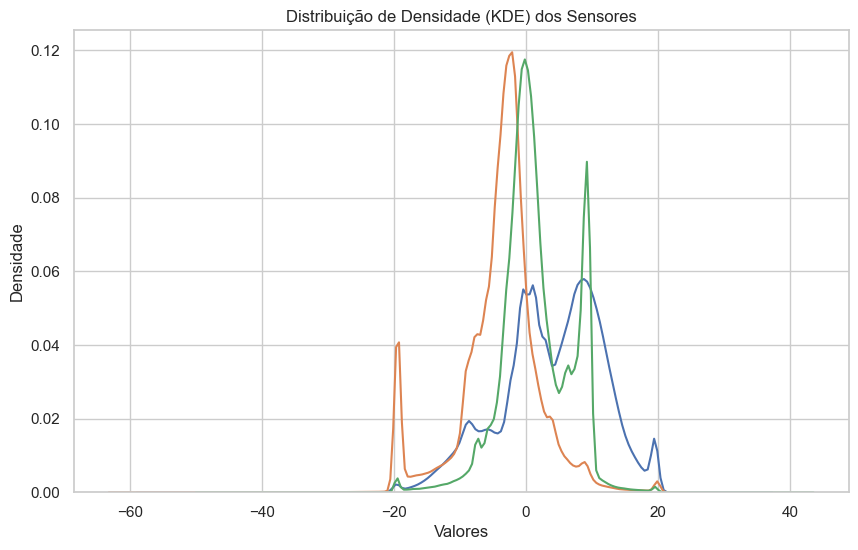

In [144]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Configurações do gráfico
plt.figure(figsize=(10, 6))
sns.set(style="whitegrid")
plt.title("Distribuição de Densidade (KDE) dos Sensores")
plt.xlabel("Valores")
plt.ylabel("Densidade")

# Plota os KDEs para cada coluna
for col in data[['acelerômetro_x',
       'acelerômetro_Y', 'acelerômetro_Z']]:
    sns.kdeplot(data[col], label=col)

# Adiciona a legenda
plt.legend()

# Exibe o gráfico
plt.show()


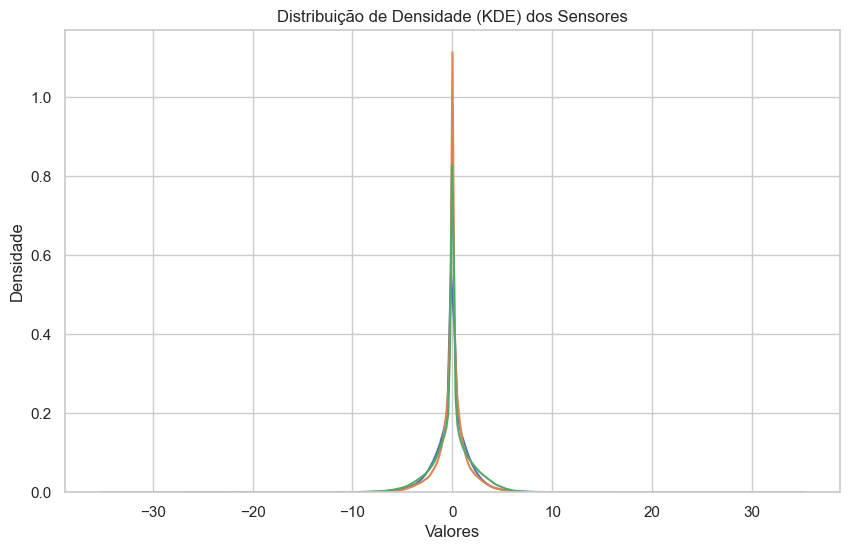

In [145]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Configurações do gráfico
plt.figure(figsize=(10, 6))
sns.set(style="whitegrid")
plt.title("Distribuição de Densidade (KDE) dos Sensores")
plt.xlabel("Valores")
plt.ylabel("Densidade")

# Plota os KDEs para cada coluna
for col in data[['giroscópio_x', 'giroscópio_Y',
       'giroscópio_Z']]:
    sns.kdeplot(data[col], label=col)

# Adiciona a legenda
plt.legend()

# Exibe o gráfico
plt.show()

In [149]:
import seaborn as sns
import pandas as pd

# Cria o dataframe
df = pd.DataFrame({
    "atividade": [0, 0, 1, 1, 1],
    "tempo": [90426757696641, 90426807196641, 90426856696641, 90426906196641, 90426955696641],
    "acelerômetro_x": [4.972757, 3.253720, 2.801216, 3.770868, 4.661511],
    "acelerômetro_Y": [-0.158317, -0.191835, -0.155922, -1.051354, 0.169689],
    "acelerômetro_Z": [6.696732, 6.107758, 5.997625, 7.731027, 9.684695],
    "giroscópio_x": [0.314944, 0.387382, 0.070999, 0.037975, 0.073129],
    "giroscópio_Y": [-1.022277, -0.618541, -0.209480, 0.254976, 0.719431],
    "giroscópio_Z": [-0.309962, -0.048972, -0.195978, -0.156563, -0.001035]
})

# Agrupa os dados por atividade
agrupado = df.groupby("atividade")

# Plotando o gráfico de densidade KDE para cada coluna
for coluna in agrupado[['giroscópio_x', 'giroscópio_Y',
       'giroscópio_Z']]:
    sns.displot(data=agrupado, x=coluna, kind="kde", hue="atividade", fill=True)

# Adiciona título e rótulos aos eixos
plt.title("Distribuição dos dados por atividade")
plt.xlabel(coluna)
plt.ylabel("Densidade de probabilidade")

# Mostra o gráfico
plt.show()


In [46]:
#selecting only activities 0 to 3
data = data[data["atividade"].isin([0,1,2,3])]

In [47]:
data.shape

(714799, 9)

In [48]:
data.head()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426757696641,4.972757,-0.158317,6.696732,0.314944,-1.022277,-0.309962
1,1600,0,90426807196641,3.253720,-0.191835,6.107758,0.387382,-0.618541,-0.048972
2,1600,0,90426856696641,2.801216,-0.155922,5.997625,0.070999,-0.209480,-0.195978
3,1600,0,90426906196641,3.770868,-1.051354,7.731027,0.037975,0.254976,-0.156563
4,1600,0,90426955696641,4.661511,0.169689,9.684695,0.073129,0.719431,-0.001035


In [ ]:
for col in df.columns:
    sns.kdeplot(df[col], fill=True)

# Adicione títulos e rótulos aos eixos
plt.title("Distribuição KDE dos dados")
plt.xlabel("Valor")
plt.ylabel("Densidade")

# Mostre o gráfico
plt.show()

In [49]:
data = data.reset_index()

In [50]:
data.head()

,index,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,0,1600,0,90426757696641,4.972757,-0.158317,6.696732,0.314944,-1.022277,-0.309962
1,1,1600,0,90426807196641,3.253720,-0.191835,6.107758,0.387382,-0.618541,-0.048972
2,2,1600,0,90426856696641,2.801216,-0.155922,5.997625,0.070999,-0.209480,-0.195978
3,3,1600,0,90426906196641,3.770868,-1.051354,7.731027,0.037975,0.254976,-0.156563
4,4,1600,0,90426955696641,4.661511,0.169689,9.684695,0.073129,0.719431,-0.001035


In [51]:
data.shape

(714799, 10)

# **Models**

In [52]:
print(np.linspace(1600,1650,num=11))

[1600. 1605. 1610. 1615. 1620. 1625. 1630. 1635. 1640. 1645. 1650.]


In [53]:
X_validation_data = data[(data['pessoa_x'].isin([1600,1605,1610,1615,1620,1625,1630,1635,1640,1645,1650]))]

In [54]:
X_validation_data.shape

(154002, 10)

In [55]:
X_validation_data.head()

,index,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,0,1600,0,90426757696641,4.972757,-0.158317,6.696732,0.314944,-1.022277,-0.309962
1,1,1600,0,90426807196641,3.253720,-0.191835,6.107758,0.387382,-0.618541,-0.048972
2,2,1600,0,90426856696641,2.801216,-0.155922,5.997625,0.070999,-0.209480,-0.195978
3,3,1600,0,90426906196641,3.770868,-1.051354,7.731027,0.037975,0.254976,-0.156563
4,4,1600,0,90426955696641,4.661511,0.169689,9.684695,0.073129,0.719431,-0.001035


In [56]:
X_validation_data.tail()

,index,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
714794,3188405,1650,3,2425320732993807,-0.791733,0.860416,9.715521,0.016944,0.004328,0.012383
714795,3188406,1650,3,2425320782976267,-0.784550,0.908300,9.717916,0.013749,-0.003129,0.008122
714796,3188407,1650,3,2425320832958727,-0.794127,0.819715,9.679607,-0.017144,0.001132,0.009188
714797,3188408,1650,3,2425320882941187,-0.827646,0.905906,9.765799,0.008422,-0.002064,0.007057
714798,3188409,1650,3,2425320932928957,-0.844405,0.764648,9.737069,0.002031,0.005393,0.011318


In [57]:
data.shape

(714799, 10)

In [58]:
X_validation_data = X_validation_data.reset_index(drop=True)

In [59]:
X_validation_data = X_validation_data.drop('index',axis=1)


In [60]:
X_validation_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 154002 entries, 0 to 154001
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   pessoa_x        154002 non-null  int64  
 1   atividade       154002 non-null  int64  
 2   tempo           154002 non-null  int64  
 3   acelerômetro_x  154002 non-null  float64
 4   acelerômetro_Y  154002 non-null  float64
 5   acelerômetro_Z  154002 non-null  float64
 6   giroscópio_x    154002 non-null  float64
 7   giroscópio_Y    154002 non-null  float64
 8   giroscópio_Z    154002 non-null  float64
dtypes: float64(6), int64(3)
memory usage: 10.6 MB


In [61]:
X_validation_data['atividade'].value_counts()

atividade
0    39670
3    38242
2    38199
1    37891
Name: count, dtype: int64

In [62]:
X_validation_data = X_validation_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]

In [63]:
print(X_validation_data.shape)

(154002, 7)


In [64]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [65]:
def apply_segmentation_with_sliding_window(df_data):
    #creating sliding window for train data
    import numpy as np

    window_size = 200
    step_size = 20

    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_size
        label_consistency = df_data[['atividade']][start_idx:end_idx].nunique()==1
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [66]:
values_to_delete = [1600,1605,1610,1615,1620,1625,1630,1635,1640,1645,1650]

In [67]:
X_train_data = data[~data['pessoa_x'].isin(values_to_delete)]

In [68]:
X_train_data.shape

(560797, 10)

In [69]:
X_train_data = X_train_data.reset_index(drop=True)
X_train_data = X_train_data.drop('index',axis=1)

In [70]:
X_train_data.shape

(560797, 9)

In [71]:
X_train_data.head()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1601,0,1896411611733301,-2.969708,-1.949329,10.726623,0.703360,-0.436308,-0.953889
1,1601,0,1896411661695801,-3.486855,-2.420987,11.660361,0.254884,-0.424590,-0.993304
2,1601,0,1896411711658874,-2.826056,-2.854338,9.792884,0.301756,-0.222190,-0.949628
3,1601,0,1896411761623926,-3.307290,-3.076998,9.926959,0.287907,-0.141230,-1.095569
4,1601,0,1896411811593717,-3.996820,-2.847155,9.280524,0.402956,0.272093,-1.006087


In [72]:
X_train_data.tail()

,pessoa_x,atividade,tempo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z
560792,1649,3,2720410419912593,1.275960,-4.642058,8.523807,-0.004732,0.000795,-0.000759
560793,1649,3,2720410469866083,1.345392,-4.697125,8.578874,-0.000471,-0.000271,0.002437
560794,1649,3,2720410519819573,1.268777,-4.527136,8.576479,0.020834,0.000795,-0.003955
560795,1649,3,2720410569773063,1.237653,-4.649241,8.624364,-0.010058,0.015708,-0.006085
560796,1649,3,2720410619726553,1.244835,-4.802469,8.322694,-0.024972,-0.001336,0.008828


In [73]:
X_train_data = X_train_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]

In [74]:
X_train_data.head()

,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,atividade
0,-2.969708,-1.949329,10.726623,0.703360,-0.436308,-0.953889,0
1,-3.486855,-2.420987,11.660361,0.254884,-0.424590,-0.993304,0
2,-2.826056,-2.854338,9.792884,0.301756,-0.222190,-0.949628,0
3,-3.307290,-3.076998,9.926959,0.287907,-0.141230,-1.095569,0
4,-3.996820,-2.847155,9.280524,0.402956,0.272093,-1.006087,0


In [75]:
segments_val,targets_val = apply_segmentation_with_sliding_window(X_validation_data)
print(targets_val.shape)
print(segments_val.shape)

(7691, 200, 1)
(7691, 200, 6)


In [76]:
segments_val,targets_val = delete_segments_not_fully_filled(segments_val,targets_val)
print(targets_val.shape)
print(segments_val.shape)

(7274, 200, 1)
(7274, 200, 6)


In [77]:
targets_val = targets_val.reshape(targets_val.shape[0],200)

In [78]:
print(targets_val.shape)

(7274, 200)


In [79]:
print(targets_val)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]
 [3 3 3 ... 3 3 3]]


In [80]:
labels_val = targets_val[:,0]

In [81]:
print(labels_val)

[0 0 0 ... 3 3 3]


In [82]:
print(labels_val.shape)

(7274,)


In [83]:
labels_val_categorical = to_categorical(labels_val,num_classes=4)

In [84]:
print(labels_val_categorical)

[[1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 ...
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]]


In [85]:
print(labels_val_categorical.shape)

(7274, 4)


In [86]:
segments_train,targets_train = apply_segmentation_with_sliding_window(X_train_data)

In [87]:
print(segments_train.shape)
print(targets_train.shape)

(28030, 200, 6)
(28030, 200, 1)


In [88]:
segments_train, targets_train = delete_segments_not_fully_filled(segments_train,targets_train)

In [89]:
print(segments_train.shape)
print(targets_train.shape)

(26498, 200, 6)
(26498, 200, 1)


In [90]:
targets_train = targets_train.reshape(targets_train.shape[0],200)

In [91]:
print(targets_train.shape)

(26498, 200)


In [92]:
labels_train = targets_train[:,0]

In [93]:
labels_train_categorical = to_categorical(labels_train,num_classes=4)

In [94]:
print(labels_train_categorical)

[[1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 ...
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]]


In [95]:
X_train = segments_train
y_train = labels_train_categorical
X_validation = segments_val
y_validation = labels_val_categorical

In [96]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(26498, 200, 6)
(26498, 4)
(7274, 200, 6)
(7274, 4)


In [97]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [98]:
X_train,y_train = shuffle_data(X_train,y_train)
X_validation,y_validation = shuffle_data(X_validation,y_validation)

In [99]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(26498, 200, 6)
(26498, 4)
(7274, 200, 6)
(7274, 4)


In [100]:
#from tensorflow.keras import regularizers

In [101]:
''' def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation='relu'))
  model.add(tf.keras.layers.BatchNormalization())  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model
 '''

' def cria_LSTM(hp):\n  model = tf.keras.Sequential()  \n  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))\n  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation=\'relu\'))\n  model.add(tf.keras.layers.BatchNormalization())  \n  model.add(tf.keras.layers.Dense(units=4, activation=\'softmax\'))\n  model.compile(loss=\'categorical_crossentropy\', optimizer=tf.keras.optimizers.Adam(hp.Float(\n                    \'learning_rate\',\n                    min_value=1e-4,\n                    max_value=1e-2,\n                    sampling=\'LOG\',\n                    default=1e-3\n                )), metrics=[\'accuracy\'])\n  return model\n '

In [102]:
def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float('l2_reg', min_value=0.0001, max_value=0.1, sampling='log')),
             recurrent_regularizer=l2(hp.Float('l2_reg', min_value=0.0001, max_value=0.1, sampling='log')), input_shape=(200,6), return_sequences=False))  
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation='relu'))  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model


In [103]:
tuner = RandomSearch(
    cria_LSTM,
    objective = 'val_accuracy', 
    seed=42,
    max_trials = 10,
    overwrite=True,        
    executions_per_trial = 1,    
    directory = LOG_DIR,
    project_name="lstm_acel_giro_multiclass")

In [104]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    verbose=1)

tensorboard = tf.keras.callbacks.TensorBoard(LOG_DIR)

my_callbacks = [early_stopping,reduce_lr,tensorboard]  


In [105]:
tuner.search(x=X_train,
            y=y_train,
            epochs=50,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=32, use_multiprocessing=True)

Trial 10 Complete [00h 44m 56s]
val_accuracy: 0.9278251528739929

Best val_accuracy So Far: 0.9278251528739929
Total elapsed time: 08h 38m 35s


In [106]:
tuner.results_summary()

Results summary
Results in ~/git/LSTM_giroscopio_acelerometro//Code/DataPrep/2024-02-26_14-11-34\lstm_acel_giro_multiclass
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 09 summary
Hyperparameters:
input_units: 224
l2_reg: 0.0002729031103694528
input_units_relu: 96
learning_rate: 0.0010277342442932575
Score: 0.9278251528739929

Trial 02 summary
Hyperparameters:
input_units: 128
l2_reg: 0.0005377164071193433
input_units_relu: 256
learning_rate: 0.001715074355925934
Score: 0.9180643558502197

Trial 04 summary
Hyperparameters:
input_units: 160
l2_reg: 0.0004704965297508378
input_units_relu: 96
learning_rate: 0.0009749332269823054
Score: 0.9117404222488403

Trial 07 summary
Hyperparameters:
input_units: 256
l2_reg: 0.0009359659238480391
input_units_relu: 32
learning_rate: 0.00036276965095376624
Score: 0.9030794501304626

Trial 00 summary
Hyperparameters:
input_units: 192
l2_reg: 0.00013051352453616747
input_units_relu: 128
learning_rate: 0.0003497444477863496

In [107]:
tuner.get_best_hyperparameters()[0].values

{'input_units': 224,
 'l2_reg': 0.0002729031103694528,
 'input_units_relu': 96,
 'learning_rate': 0.0010277342442932575}

In [108]:
best_model = tuner.get_best_models(num_models=1)[0]

In [109]:
best_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 224)               206976    
                                                                 
 dense (Dense)               (None, 96)                21600     
                                                                 
 dense_1 (Dense)             (None, 4)                 388       
                                                                 
Total params: 228964 (894.39 KB)
Trainable params: 228964 (894.39 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [110]:
loss, accuracy = best_model.evaluate(X_validation, y_validation)

228/228 [==============================] - 18s 78ms/step - loss: 0.4928 - accuracy: 0.9278


In [111]:
predictions = best_model.predict(X_validation)

228/228 [==============================] - 18s 76ms/step


In [112]:
print(y_validation)

[[0. 0. 0. 1.]
 [0. 1. 0. 0.]
 [0. 1. 0. 0.]
 ...
 [0. 1. 0. 0.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]]


In [113]:
print(y_validation.shape)

(7274, 4)


In [114]:
y_validation_inverse = np.argmax(y_validation, axis=1)

In [115]:
print(y_validation_inverse)

[3 1 1 ... 1 1 0]


In [116]:
print(len(y_validation_inverse))

7274


In [117]:
print(predictions)

[[1.0663864e-05 3.8164644e-06 4.2167714e-05 9.9994338e-01]
 [3.0355526e-08 9.9994302e-01 9.9735953e-06 4.6985781e-05]
 [2.8272702e-08 9.9993277e-01 1.0504834e-05 5.6776469e-05]
 ...
 [2.5446614e-08 9.9957067e-01 1.5818377e-04 2.7111845e-04]
 [1.8362303e-05 9.9944013e-01 1.4196537e-04 3.9943075e-04]
 [9.9989331e-01 1.1466263e-07 9.5992858e-05 1.0628993e-05]]


In [118]:
classes_x=np.argmax(predictions,axis=1)

In [119]:
print(classes_x)

[3 1 1 ... 1 1 0]


In [120]:
print(len(classes_x))

7274


In [121]:
print(classes_x.shape)

(7274,)


In [122]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm = confusion_matrix(y_validation_inverse, classes_x)

In [123]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

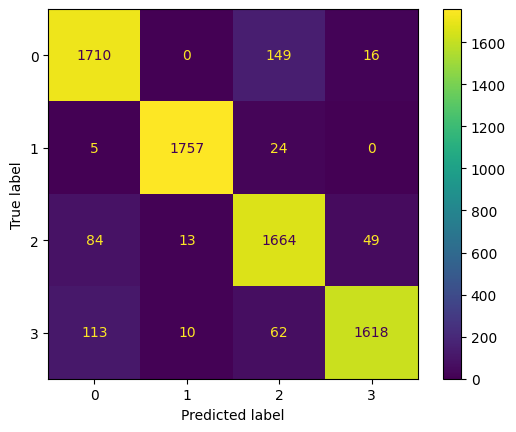

In [124]:
disp.plot()

In [125]:
print(classification_report(y_validation_inverse, classes_x))

              precision    recall  f1-score   support

           0       0.89      0.91      0.90      1875
           1       0.99      0.98      0.99      1786
           2       0.88      0.92      0.90      1810
           3       0.96      0.90      0.93      1803

    accuracy                           0.93      7274
   macro avg       0.93      0.93      0.93      7274
weighted avg       0.93      0.93      0.93      7274



In [126]:
best_model.save(WORKDIR+"/Model/best_models_saved")

INFO:tensorflow:Assets written to: ~/git/LSTM_giroscopio_acelerometro//Model/best_models_saved\assets


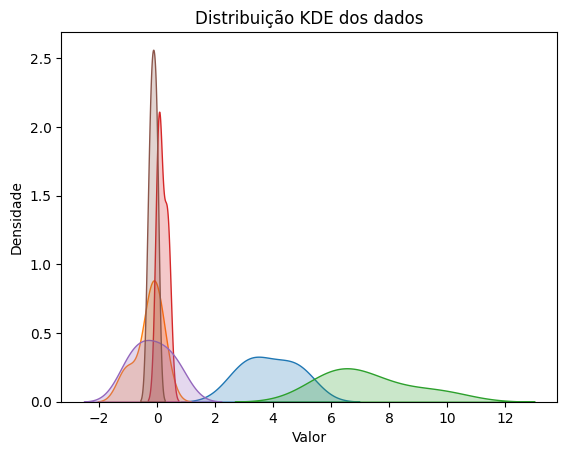

In [128]:
import seaborn as sns
import pandas as pd

# Crie um dataframe
df = pd.DataFrame({
    "acelerômetro_x": [4.972757, 3.253720, 2.801216, 3.770868, 4.661511],
    "acelerômetro_Y": [-0.158317, -0.191835, -0.155922, -1.051354, 0.169689],
    "acelerômetro_Z": [6.696732, 6.107758, 5.997625, 7.731027, 9.684695],
    "giroscópio_x": [0.314944, 0.387382, 0.070999, 0.037975, 0.073129],
    "giroscópio_Y": [-1.022277, -0.618541, -0.209480, 0.254976, 0.719431],
    "giroscópio_Z": [-0.309962, -0.048972, -0.195978, -0.156563, -0.001035]
})

# Gere um gráfico KDE para cada coluna
for col in df.columns:
    sns.kdeplot(df[col], fill=True)

# Adicione títulos e rótulos aos eixos
plt.title("Distribuição KDE dos dados")
plt.xlabel("Valor")
plt.ylabel("Densidade")

# Mostre o gráfico
plt.show()